# Power analysis: choosing Study I's number of regions and runs

**Question.** How many source regions `k` and runs per region `r` should Study I's flagship simulate? `k` is
capped at **396**, the 446 MultiConn scale-4 regions minus the 50 tuning regions (which also form the pilot).
The degradation and surrogate experiments reuse the flagship's runs, so they inherit its design; the noise sweep
is only costed here (the pilot is at SNR 5 only).

**Pilot.** 50 tuning regions (none in the current probe set) × 4 runs, simulated with exactly Study I's
simulation (`simulate_tuning_spikes.py --repetitions 4 --seed 2027`), solved and scored with Study I's solvers and
metrics (`solve_pilot.py` → `results/simf/power_pilot`).

**Tests, as in `index.qmd`** (wCSET vs. CSET, sLORETA, dSPM, wMNE; one value per region = mean over its runs):
- localization error at 25% of the peak: Wilcoxon signed-rank (Pratt), Holm across the 4 competitors;
  Hodges–Lehmann estimate with its 99% CI; non-inferior if the CI excludes a wCSET deficit > δ = 5 mm;
- spatial correlation over time: cluster-based permutation test, Holm across the 4 pairs.

**Decision rule** (fixed before running):
1. Required tests, in the direction the pilot shows:
   - localization **non-inferiority vs. CSET and dSPM**, at the pilot-estimated difference (wCSET slightly worse);
   - localization **superiority vs. sLORETA and wMNE** (Holm), at the pilot effect;
   - "the pilot's difference" is held fixed across designs (scenario P, §3): the pilot's 4-run pseudo-median;
   - correlation **cluster test vs. all 4**, at **half** the pilot effect (the pilot effect is optimistic).
2. Feasible design: every required test has power ≥ **0.90**.
3. Choice: the feasible design with the fewest runs `k·r` (compute cost is proportional to it); ties → more
   regions. If none is feasible, the design maximizing the smallest required power, and the shortfall is reported.

**Why mostly regions.** A region's mean difference has variance τ² + σ²/r (τ² between regions, σ² within).
More runs only shrink σ²/r; more regions shrink both. A new region costs the same as a new run here (the lead field
covers every region), so the optimal design spreads runs over regions until `k` hits its cap, then adds runs.

Localization errors are bimodal (0 mm or far away), so power is estimated by a two-stage bootstrap of the pilot
(§3), not a normal model; the normal model (§2) only screens the grid.

Set `QUICK=1` in the environment for a fast smoke run (small B); `POWER_PILOT` / `POWER_OUT` override the input and
output folders.

In [1]:
import json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from joblib import Parallel, delayed
from scipy.stats import chi2, norm

import mindmap as mm
from mindmap.core import stats as st

PROJECT = Path("/home/nino/Manuscripts/wCSET")
sys.path.insert(0, str(PROJECT))
from scripts.figures import COLORS, METHOD_LABELS, LINE_COLOR

mne.set_log_level("error")
QUICK = os.environ.get("QUICK") == "1"
PILOT = Path(os.environ.get("POWER_PILOT", PROJECT / "results/simf/power_pilot"))
OUT = Path(os.environ.get("POWER_OUT", PROJECT / ("results/simf/power_quick" if QUICK else "results/simf/power")))
OUT.mkdir(parents=True, exist_ok=True)

REF, COMPETITORS = "wcset", ["cset", "sloreta", "dspm", "wmne"]
NI_REQUIRED = ["cset", "dspm"]          # wCSET trails these in the pilot: non-inferiority is the claim
SUP_REQUIRED = ["sloreta", "wmne"]      # wCSET beats these in the pilot: superiority is the claim
DELTA_LOC_MM = 5.0                      # non-inferiority margin (index.qmd)
CI_LEVEL = 0.99                         # index.qmd's CI_LEVEL
ALPHA = 0.05
POWER_TARGET = 0.90

K_MAX = 396                             # 446 regions - 50 tuning/pilot regions
KS = [50, 100, 150, 200, 250, 300, 350, K_MAX]
RS = [1, 2, 3, 4, 6, 8]                 # r > 4 extrapolates the 4 pilot runs
OLD_DESIGN = (100, 8)                   # the design used so far, kept as a reference point
B = 200 if QUICK else 2000              # replicates per design (localization error)
SHIFTS = np.arange(-10.0, 10.01, 0.5)   # true difference (mm, positive = wCSET better) for the MDE curves

B_CLUSTER, N_PERM = (20, 200) if QUICK else (300, 1000)
CLUSTER_KS = [20, 50, 100]              # correlation power is ~1 already at small k (checked below)
CLUSTER_RS = [1, 2, 4, 8]
EFFECT_SCALES = [1.0, 0.5, 0.25]
CORR_REQUIRED_SCALE = 0.5
SPIKE = (-0.02, 0.05)                   # s, a hit is a wCSET-better cluster overlapping this window
N_JOBS = 25

# Wall-clock cost per flagship run (25 workers, this machine). Measured: simulation from the pilot's file
# timestamps, solve + score from power_pilot.log (9.0 s/run, 5 methods, full time course). Estimated: degradation
# and surrogates solve wCSET + CSET at 1-2 time points only (~1.5 s/run per connectome, scaled from single-thread
# timings), over 11 degradation levels and 6 connectomes (5 surrogates + original).
COST_S = {"simulation": 1.6, "solve + score": 9.0, "degradation (11 levels)": 1.5 * 11,
          "surrogates (6 connectomes)": 1.5 * 6}
NOISE_SWEEP_S_PER_RUN = 1.6 + 2.5       # simulation + 5 methods at 2 time points (estimate)
NOISE_SWEEP_LEVELS = 9
C_RUN = sum(COST_S.values())

def cost_hours(k, r):
    return k * r * C_RUN / 3600

print(f"QUICK={QUICK}  B={B}  out={OUT}  cost per flagship run = {C_RUN:.1f} s")

QUICK=False  B=2000  out=/home/nino/Manuscripts/wCSET/results/simf/power  cost per flagship run = 36.1 s


## 1. Pilot data

Per-run paired differences, oriented so that **positive = wCSET better**: competitor − wCSET for localization error,
wCSET − competitor for correlation. Differences are taken within each run, so resampling runs keeps the pairing.

In [2]:
suite = mm.metric.MetricSuite.load(PILOT)
print(suite.metadata.get("pilot"))

loc = suite.to_df(metrics="localization_error", filters={"phase": "qrp"})
loc_w = loc.pivot_table(index=["region", "run"], columns="Method", values="Value")
regions = loc_w.index.get_level_values("region").unique()
n_runs = loc_w.groupby(level="region").size()
assert n_runs.nunique() == 1, n_runs.value_counts()
R_PILOT = int(n_runs.iloc[0])
N_PILOT = len(regions)
print(f"{N_PILOT} regions x {R_PILOT} runs")

# D_loc: (regions, runs, competitors), positive = wCSET better (lower error)
D_loc = np.stack([np.stack([(loc_w.loc[reg][c] - loc_w.loc[reg][REF]).to_numpy() for c in COMPETITORS], -1)
                  for reg in regions])

corr = suite.to_df(metrics="correlation")
times = np.sort(corr["times"].unique())
def _curves(m):  # (regions, runs, times)
    sub = corr[corr["Method"] == m]
    return np.stack([sub[sub["region"] == reg].pivot_table(index="rep", columns="times", values="Value").to_numpy()
                     for reg in regions])
C_ref = _curves(REF)
D_corr = np.stack([C_ref - _curves(c) for c in COMPETITORS], axis=2)   # (regions, runs, competitors, times)
print(D_loc.shape, D_corr.shape)

{'simulations': '/media/nino/DATA/SIMF/derivatives/simulations-pilot', 'n_runs': 200, 'n_regions': 50, 'methods': ['wcset', 'cset', 'sloreta', 'dspm', 'wmne'], 'crop': [-0.02, 0.15]}
50 regions x 4 runs


(50, 4, 4) (50, 4, 4, 44)


In [3]:
# Bimodality of localization error (why a normal model is a poor fit): share of runs at 0 mm and > 30 mm
bimodal = pd.DataFrame({"0 mm (%)": (loc.groupby("Method")["Value"].apply(lambda v: (v == 0).mean() * 100)),
                        "> 30 mm (%)": (loc.groupby("Method")["Value"].apply(lambda v: (v > 30).mean() * 100)),
                        "median (mm)": loc.groupby("Method")["Value"].median()}).round(1)
bimodal

,0 mm (%),> 30 mm (%),median (mm)
Method,,,
cset,27.0,14.0,8.0
dspm,12.0,9.5,9.7
sloreta,12.5,31.0,11.2
wcset,29.0,21.5,5.0
wmne,7.0,77.0,72.9


## 2. Variance components and a closed-form screen

τ² (between regions) and σ² (within regions, between runs) of the paired localization difference, by the method of
moments, and the pilot's own test at its design (50 × 4).

`variance_ratio` = σ²/τ²: the number of runs at which the within-region term σ²/r equals the between-region term.
Beyond a few runs, extra runs barely shrink the variance of a region mean; only more regions do.

In [4]:
m_i = D_loc.mean(1)                                  # (regions, competitors)
sigma2 = D_loc.var(1, ddof=1).mean(0)                # pooled within-region variance
tau2 = np.maximum(m_i.var(0, ddof=1) - sigma2 / R_PILOT, 0)
pilot_tbl = []
for j, c in enumerate(COMPETITORS):
    t = st.paired_test(m_i[:, j], np.zeros(len(m_i)), test="wilcoxon", zero_method="pratt")
    e = st.estimate(m_i[:, j], np.zeros(len(m_i)), estimator="hodges_lehmann", alpha=1 - CI_LEVEL)
    pilot_tbl.append(dict(competitor=c, hl=e["estimate"], ci_low=e["ci_low"], ci_high=e["ci_high"], p=t["p_value"],
                          sd_between=np.sqrt(tau2[j]), sd_within=np.sqrt(sigma2[j]),
                          variance_ratio=sigma2[j] / tau2[j] if tau2[j] > 0 else np.inf))
pilot_tbl = pd.DataFrame(pilot_tbl).set_index("competitor")
pilot_tbl["p_holm"] = st.correct_pvalues(pilot_tbl["p"].to_numpy(), method="holm")[0]
pilot_tbl.round(3)

,hl,ci_low,ci_high,p,sd_between,sd_within,variance_ratio,p_holm
competitor,,,,,,,,
cset,-2.607,-9.439,2.888,0.228,10.572,23.381,4.891,0.455
sloreta,7.689,2.587,14.390,0.000,7.862,30.757,15.305,0.000
dspm,-0.858,-10.217,4.652,0.780,15.849,22.311,1.982,0.780
wmne,45.136,35.968,53.831,0.000,15.374,36.254,5.561,0.000


## 3. Resampler

A plain two-stage bootstrap (regions, then runs) counts the within-region noise twice: the pilot's region means
already contain it (σ²/4), and the resampled runs add it again. So each replicate region is built as

region mean = s · grand mean + λ · (pilot region mean − grand mean) + mean of r resampled residuals × √(n/(n−1)),

with λ = √(τ²/var(region means)) shrinking the region means to the between-region variance τ², and residuals drawn
with replacement from that region's own runs (whole runs, all competitors together, so the pairing is kept and
the bimodal shape is preserved). Its region means then have variance τ² + σ²/r, the design's true variance.
s scales the average effect (1 = the pilot's; used for the correlation robustness check).
r > 4 is an extrapolation: it reuses the 4 pilot runs' residuals.

**Scenarios.**
- (A) the pilot's effects as resampled. With skewed, bimodal errors, the pseudo-median (the Hodges–Lehmann target)
  of an r-run region mean changes with r (table below: vs. CSET, −0.4 mm at r = 1 but −2.1 mm at r = 4). So under A
  each design faces a different true difference, and small r looks artificially easy for non-inferiority.
- (P) **used for the decision**: centered at r, then shifted to the pilot's own 4-run pseudo-median, so every design
  faces the same true difference.
- (B) every difference centered at 0: non-inferiority power at no true difference, and the type I error check.
- (C) B plus a true shift Δ, for the minimum detectable effect.

In [5]:
def make_resampler(D):
    # D: (regions, runs, ...). Returns draw(k, r, rng, shift=None, scale=1.0) -> (k, ...) region means.
    n = D.shape[1]
    m = D.mean(1)
    grand = m.mean(0)
    resid = (D - m[:, None]) * np.sqrt(n / (n - 1))
    var_m = m.var(0, ddof=1)
    tau2_ = np.maximum(var_m - D.var(1, ddof=1).mean(0) / n, 0)
    lam = np.sqrt(np.divide(tau2_, var_m, out=np.zeros_like(var_m), where=var_m > 0))
    dev = lam * (m - grand)                       # shrunken region deviations

    def draw(k, r, rng, shift=None, scale=1.0):
        reg = rng.integers(0, D.shape[0], k)
        runs = rng.integers(0, n, (k, r))
        out = scale * grand + dev[reg] + resid[reg[:, None], runs].mean(1)
        return out if shift is None else out + shift
    return draw

draw_loc = make_resampler(D_loc)
draw_corr = make_resampler(D_corr)

# Centering for scenarios B and C: the resampler's own population pseudo-median (Hodges-Lehmann target) at each r.
# Not the pilot's 4-run estimate: with skewed, bimodal errors the pseudo-median of an r-run mean shifts with r, so a
# single centering leaves a small true difference at r != 4, which large k then detects (type I error inflation).
def pseudo_median(x):
    i, j = np.triu_indices(len(x))
    return np.median((x[i] + x[j]) / 2)

def population_center(r, n=3000, reps=5, seed=123):
    rng = np.random.default_rng([r, seed])
    draws = [draw_loc(n, r, rng) for _ in range(reps)]
    return np.array([np.mean([pseudo_median(d[:, j]) for d in draws]) for j in range(len(COMPETITORS))])

CENTER = {r: population_center(r) for r in sorted(set(RS) | {R_PILOT})}
print("True difference (pseudo-median, mm, positive = wCSET better) of an r-run region mean, scenario A:")
print(pd.DataFrame(CENTER, index=COMPETITORS).round(2))

# Sanity check: at the pilot's own design, resampled region means have the pilot's variance
rng = np.random.default_rng(0)
v = np.stack([draw_loc(N_PILOT, R_PILOT, rng) for _ in range(400)]).var(1, ddof=1).mean(0)
ratio = v / m_i.var(0, ddof=1)
print("resampled var / pilot var of region means:", np.round(ratio, 2))
assert np.all(np.abs(ratio - 1) < 0.1), ratio

True difference (pseudo-median, mm, positive = wCSET better) of an r-run region mean, scenario A:
             1      2      3      4      6      8
cset     -0.36  -1.39  -1.75  -2.06  -2.20  -2.35
sloreta   7.24   8.03   8.13   8.19   8.07   8.08
dspm      2.04   0.35  -0.23  -0.45  -0.84  -0.98
wmne     45.37  45.46  45.35  45.09  44.93  45.13
resampled var / pilot var of region means: [0.97 0.99 0.97 0.98]


## 4. Localization error: Monte Carlo power over the design grid

Per replicate and competitor: Wilcoxon signed-rank (Pratt) on the k region means, Holm across the 4 competitors;
Hodges–Lehmann estimate with its 99% distribution-free CI; non-inferior if the CI's lower bound > −5 mm.
Scenario P gives the required powers (superiority and non-inferiority at the pilot's effects, fixed across designs);
A is kept for reference; B gives non-inferiority power at a true difference of 0, and checks the type I error.

First, a normal-model screen: SE = sqrt((τ² + σ²/r) / k), non-inferiority power Φ((δ + μ)/SE − z) with μ the true
difference (positive = wCSET better) and z the 99% CI quantile, so 0.90 power needs
k = (z + z_0.90)² (τ² + σ²/r) / (δ + μ)² regions. The bootstrap then decides.

In [6]:
Z_CI = norm.ppf(1 - (1 - CI_LEVEL) / 2)              # 99% two-sided CI = one-sided 0.005 test
Z_POW = norm.ppf(POWER_TARGET)

def ni_power_normal(k, r, tau2_, sigma2_, mu):
    se = np.sqrt((tau2_ + sigma2_ / r) / k)
    return norm.cdf((DELTA_LOC_MM + mu) / se - Z_CI)

def k_needed_normal(r, tau2_, sigma2_, mu):
    gap = DELTA_LOC_MM + mu
    return np.inf if gap <= 0 else (Z_CI + Z_POW) ** 2 * (tau2_ + sigma2_ / r) / gap ** 2

screen = []
for c in NI_REQUIRED:
    jj = COMPETITORS.index(c)
    for mu_label, mu in [("pilot", CENTER[R_PILOT][jj]), ("0", 0.0)]:
        row = {"competitor": c, "true diff": mu_label}
        for r in RS:
            row[f"k needed, r={r}"] = k_needed_normal(r, tau2[jj], sigma2[jj], mu)
        screen.append(row)
screen = pd.DataFrame(screen).set_index(["competitor", "true diff"])
print(f"Regions needed for {POWER_TARGET:.0%} non-inferiority power (normal model, 99% CI); cap = {K_MAX}:")
screen.round(0)

Regions needed for 90% non-inferiority power (normal model, 99% CI); cap = 396:


k needed, r=1  k needed, r=2  k needed, r=3  \
competitor true diff                                                
cset       pilot             1134.0          663.0          506.0   
           0                  392.0          229.0          175.0   
dspm       pilot              539.0          360.0          300.0   
           0                  446.0          298.0          248.0   

                      k needed, r=4  k needed, r=6  k needed, r=8  
competitor true diff                                               
cset       pilot              428.0          349.0          310.0  
           0                  148.0          121.0          107.0  
dspm       pilot              271.0          241.0          226.0  
           0                  224.0          199.0          187.0

In [7]:
def loc_tests(d):
    # d: (k, competitors) region-mean differences, positive = wCSET better.
    zeros = np.zeros(len(d))
    p, est, lo, hi = [], [], [], []
    for j in range(d.shape[1]):
        p.append(st.paired_test(d[:, j], zeros, test="wilcoxon", zero_method="pratt")["p_value"])
        e = st.estimate(d[:, j], zeros, estimator="hodges_lehmann", alpha=1 - CI_LEVEL)
        est.append(e["estimate"]); lo.append(e["ci_low"]); hi.append(e["ci_high"])
    p, est, lo, hi = map(np.asarray, (p, est, lo, hi))
    sig = st.correct_pvalues(p, method="holm", alpha=ALPHA)[1]
    # superiority = Holm-significant AND in wCSET's favour (two-sided test, directional claim)
    return dict(p=p, sig=sig & (est > 0), noninf=lo > -DELTA_LOC_MM, half=(hi - lo) / 2)

def run_design(k, r, scenario, shift=0.0, b=B, seed=0):
    rng = np.random.default_rng([k, r, seed, int(1000 * (shift + 10)), ord(scenario)])
    center = {"A": None, "P": -CENTER[r] + CENTER[R_PILOT], "B": -CENTER[r], "C": -CENTER[r] + shift}[scenario]
    res = [loc_tests(draw_loc(k, r, rng, center)) for _ in range(b)]
    out = []
    for j, c in enumerate(COMPETITORS):
        out.append(dict(k=k, r=r, scenario=scenario, shift=shift, competitor=c,
                        power_holm=np.mean([x["sig"][j] for x in res]),
                        reject_uncorrected=np.mean([x["p"][j] < ALPHA for x in res]),
                        power_noninf=np.mean([x["noninf"][j] for x in res]),
                        ci_half_width=np.median([x["half"][j] for x in res])))
    return out

jobs = [(k, r, s) for s in ("P", "A", "B") for k in KS for r in RS]
grid = pd.DataFrame([row for rows in Parallel(n_jobs=N_JOBS)(delayed(run_design)(k, r, s) for k, r, s in jobs)
                     for row in rows])
grid.to_csv(OUT / "power_grid.tsv", sep="\t", index=False)
mc_se = np.sqrt(POWER_TARGET * (1 - POWER_TARGET) / B)
print(f"{len(jobs)} designs x {B} replicates; Monte Carlo SE of a power near {POWER_TARGET}: {mc_se:.3f}")

144 designs x 2000 replicates; Monte Carlo SE of a power near 0.9: 0.007


In [8]:
# Checks. (1) Type I error: scenario B (no true difference), uncorrected rejection rate should be ~ alpha.
chk = grid[(grid.scenario == "B")]
print("Scenario B, uncorrected rejection rate (should be ~0.05):")
print(chk.groupby("competitor")["reject_uncorrected"].describe()[["mean", "min", "max"]].round(3))

# (2) Reproduces the previous sensitivity analysis at the old design (non-inferiority at true difference 0:
# CSET 0.79, sLORETA 1.00, dSPM 0.47, wMNE 0.46), within Monte Carlo error.
old = grid[(grid.k == OLD_DESIGN[0]) & (grid.r == OLD_DESIGN[1]) & (grid.scenario == "B")].set_index("competitor")
print("\nOld design 100 x 8, non-inferiority power at true difference 0:")
print(old["power_noninf"].round(3).to_dict())

# (3) Monte Carlo vs. normal screen, non-inferiority at the pilot estimate (scenario P)
cmp = []
for c in NI_REQUIRED:
    jj = COMPETITORS.index(c)
    for k, r in [OLD_DESIGN, (K_MAX, 2), (K_MAX, 4), (K_MAX, 8)]:
        mc = grid[(grid.k == k) & (grid.r == r) & (grid.scenario == "P") & (grid.competitor == c)]["power_noninf"].item()
        cmp.append(dict(competitor=c, k=k, r=r, monte_carlo=mc,
                        normal=ni_power_normal(k, r, tau2[jj], sigma2[jj], CENTER[R_PILOT][jj])))
print("\nNon-inferiority power at the pilot estimate: bootstrap vs. normal model")
pd.DataFrame(cmp).round(3)

Scenario B, uncorrected rejection rate (should be ~0.05):
             mean    min    max
competitor                     
cset        0.053  0.038  0.062
dspm        0.056  0.044  0.072
sloreta     0.051  0.039  0.060
wmne        0.051  0.038  0.060

Old design 100 x 8, non-inferiority power at true difference 0:
{'cset': 0.793, 'sloreta': 0.998, 'dspm': 0.488, 'wmne': 0.462}

Non-inferiority power at the pilot estimate: bootstrap vs. normal model


,competitor,k,r,monte_carlo,normal
0,cset,100,8,0.334,0.350
1,cset,396,2,0.758,0.657
2,cset,396,4,0.914,0.872
3,cset,396,8,0.946,0.963
4,dspm,100,8,0.409,0.497
5,dspm,396,2,0.850,0.929
6,dspm,396,4,0.958,0.982
7,dspm,396,8,0.974,0.994


## 5. Spatial correlation over time: cluster-based permutation test

Nested Monte Carlo: per replicate, a cluster permutation test of each competitor's (k × times) region-mean
difference (MNE's `permutation_cluster_1samp_test`, two-tailed t threshold at p < 0.05, as `index.qmd`), each
pair's most significant cluster, Holm across the 4 pairs. A hit is a Holm-significant, wCSET-better cluster
overlapping the spike (−20 to 50 ms). The pilot's average effect is scaled by 1, 0.5 and 0.25; the requirement uses
0.5. Fewer permutations than the paper's 3,000 are enough to estimate power.

In [9]:
in_spike = (times >= SPIKE[0]) & (times <= SPIKE[1])

def cluster_rep(k, r, scale, seed):
    rng = np.random.default_rng([k, r, int(100 * scale), seed, 7])
    X = draw_corr(k, r, rng, scale=scale)                  # (k, competitors, times)
    best_p, best_hit = [], []
    for j in range(len(COMPETITORS)):
        t_obs, clusters, pv, _ = mne.stats.permutation_cluster_1samp_test(
            X[:, j], n_permutations=N_PERM, tail=0, out_type="mask", seed=int(rng.integers(1 << 31)), verbose=False)
        if not len(pv):
            best_p.append(1.0); best_hit.append(False); continue
        i = int(np.argmin(pv))
        mask = np.zeros(len(times), bool); mask[clusters[i]] = True   # MNE returns slices for 1-D data
        best_p.append(pv[i]); best_hit.append(bool(t_obs[mask].mean() > 0 and (mask & in_spike).any()))
    sig = st.correct_pvalues(np.array(best_p), method="holm", alpha=ALPHA)[1]
    return sig & np.array(best_hit)

cl_jobs = [(k, r, s) for k in CLUSTER_KS for r in CLUSTER_RS for s in EFFECT_SCALES]
hits = Parallel(n_jobs=N_JOBS)(delayed(cluster_rep)(k, r, s, b) for k, r, s in cl_jobs for b in range(B_CLUSTER))
hits = np.array(hits).reshape(len(cl_jobs), B_CLUSTER, len(COMPETITORS)).mean(1)
cluster_power = pd.DataFrame(hits, columns=COMPETITORS,
                             index=pd.MultiIndex.from_tuples(cl_jobs, names=["k", "r", "effect_scale"]))
cluster_power.to_csv(OUT / "cluster_power.tsv", sep="\t")
cluster_power.round(3).unstack("effect_scale")

/tmp/ipykernel_59921/1008093894.py:8: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv


/tmp/ipykernel_59921/1008093894.py:8: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv


/tmp/ipykernel_59921/1008093894.py:8: RuntimeWarning: No clusters found, returning empty H0, clusters, and cluster_pv


cset               sloreta               dspm              \
effect_scale   0.25   0.50   1.00    0.25   0.50 1.00   0.25   0.50 1.00   
k   r                                                                      
20  1         0.253  0.697  0.977   0.613  0.983  1.0  0.623  0.960  1.0   
    2         0.270  0.497  0.963   0.403  0.947  1.0  0.417  0.927  1.0   
    4         0.213  0.333  0.947   0.307  0.920  1.0  0.283  0.923  1.0   
    8         0.130  0.313  0.957   0.213  0.880  1.0  0.167  0.867  1.0   
50  1         0.527  0.940  1.000   0.963  1.000  1.0  0.940  1.000  1.0   
    2         0.417  0.923  1.000   0.953  1.000  1.0  0.920  1.000  1.0   
    4         0.273  0.953  1.000   0.947  1.000  1.0  0.907  1.000  1.0   
    8         0.270  0.947  1.000   0.887  1.000  1.0  0.890  1.000  1.0   
100 1         0.760  1.000  1.000   1.000  1.000  1.0  1.000  1.000  1.0   
    2         0.683  1.000  1.000   1.000  1.000  1.0  1.000  1.000  1.0   
    4         0.640  1.000  1.000   1.000  1.000  1.0  0.997  1.000  1.0   
    8         0.637  1.000  1.000   1.000  1.000  1.0  1.000  1.000  1.0   

               wmne              
effect_scale   0.25   0.50 1.00  
k   r                            
20  1         0.827  1.000  1.0  
    2         0.677  0.987  1.0  
    4         0.567  0.987  1.0  
    8         0.403  0.977  1.0  
50  1         0.993  1.000  1.0  
    2         0.990  1.000  1.0  
    4         0.993  1.000  1.0  
    8         0.977  1.000  1.0  
100 1         1.000  1.000  1.0  
    2         1.000  1.000  1.0  
    4         1.000  1.000  1.0  
    8         1.000  1.000  1.0

## 6. Decision

Required powers per design (§0): non-inferiority vs. CSET and dSPM and superiority vs. sLORETA and wMNE (scenario P),
and the correlation cluster test vs. all 4 at half the pilot effect. Correlation power was simulated on a coarser
grid; a design inherits the power of the largest simulated design it contains (`k' ≤ k`, `r' ≤ r`), which is
conservative because power grows with both.

In [10]:
P_ = grid[grid.scenario == "P"]
def req_power(k, r):
    sel = P_[(P_.k == k) & (P_.r == r)].set_index("competitor")
    out = {f"NI vs {c}": sel.loc[c, "power_noninf"] for c in NI_REQUIRED}
    out.update({f"superiority vs {c}": sel.loc[c, "power_holm"] for c in SUP_REQUIRED})
    kc = max([kk for kk in CLUSTER_KS if kk <= k], default=None)
    rc = max([rr for rr in CLUSTER_RS if rr <= r], default=None)
    corr_min = (cluster_power.xs(CORR_REQUIRED_SCALE, level="effect_scale").loc[(kc, rc)].min()
                if kc is not None and rc is not None else np.nan)
    out["correlation (min over 4)"] = corr_min
    return out

design = pd.DataFrame([dict(k=k, r=r, runs=k * r, hours=cost_hours(k, r), **req_power(k, r)) for k in KS for r in RS])
req_cols = [c for c in design.columns if c.startswith(("NI", "superiority", "correlation"))]
design["min_power"] = design[req_cols].min(1)
design["limiting_test"] = design[req_cols].idxmin(1)
design["feasible"] = design["min_power"] >= POWER_TARGET
design.to_csv(OUT / "design_table.tsv", sep="\t", index=False)

if design["feasible"].any():
    chosen = design[design.feasible].sort_values(["runs", "k"], ascending=[True, False]).iloc[0]
    feasible = True
else:
    chosen = design.sort_values(["min_power", "runs"], ascending=[False, True]).iloc[0]
    feasible = False
K_CHOSEN, R_CHOSEN = int(chosen.k), int(chosen.r)
print(("Chosen (cheapest feasible) design" if feasible else
       f"No design reaches {POWER_TARGET} on every required test; best design") +
      f": k = {K_CHOSEN} regions x r = {R_CHOSEN} runs = {K_CHOSEN * R_CHOSEN} runs, "
      f"~{chosen.hours:.1f} h of Study I compute; limiting test: {chosen.limiting_test} ({chosen.min_power:.3f})")
if R_CHOSEN > R_PILOT:
    print(f"Note: r = {R_CHOSEN} > {R_PILOT} pilot runs, an extrapolation of the within-region residuals.")

# Cheapest feasible design for each r, for the annex
best_per_r = (design[design.feasible].sort_values("k").groupby("r").head(1)
              .set_index("r")[["k", "runs", "hours", "min_power", "limiting_test"]])
print("\nCheapest feasible k for each r:")
print(best_per_r.round(3) if len(best_per_r) else "none")
design[(design.k == K_CHOSEN) | ((design.k == OLD_DESIGN[0]) & (design.r == OLD_DESIGN[1]))].round(3)

Chosen (cheapest feasible) design: k = 396 regions x r = 4 runs = 1584 runs, ~15.9 h of Study I compute; limiting test: NI vs cset (0.913)

Cheapest feasible k for each r:
     k  runs   hours  min_power limiting_test
r                                            
4  396  1584  15.884      0.914    NI vs cset
6  396  2376  23.826      0.924    NI vs cset
8  396  3168  31.768      0.946    NI vs cset


,k,r,runs,hours,NI vs cset,NI vs dspm,superiority vs sloreta,superiority vs wmne,correlation (min over 4),min_power,limiting_test,feasible
11,100,8,800,8.022,0.334,0.409,1.0,1.0,1.0,0.334,NI vs cset,False
42,396,1,396,3.971,0.786,0.894,1.0,1.0,1.0,0.786,NI vs cset,False
43,396,2,792,7.942,0.758,0.850,1.0,1.0,1.0,0.758,NI vs cset,False
44,396,3,1188,11.913,0.836,0.936,1.0,1.0,1.0,0.836,NI vs cset,False
45,396,4,1584,15.884,0.914,0.958,1.0,1.0,1.0,0.914,NI vs cset,True
46,396,6,2376,23.826,0.924,0.966,1.0,1.0,1.0,0.924,NI vs cset,True
47,396,8,3168,31.768,0.946,0.974,1.0,1.0,1.0,0.946,NI vs cset,True


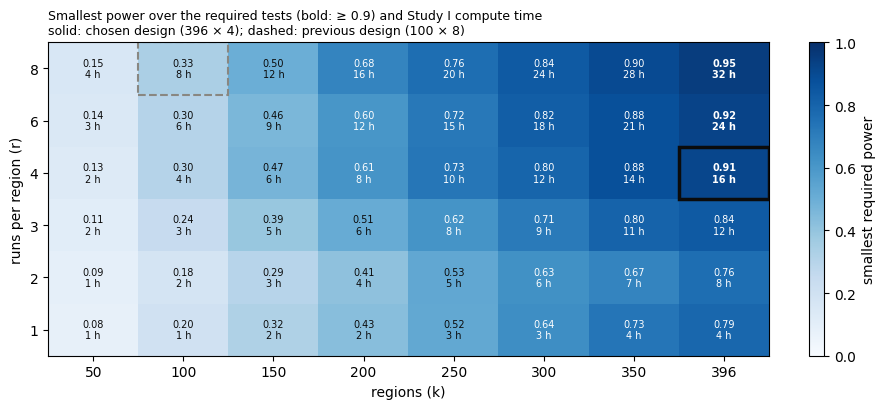

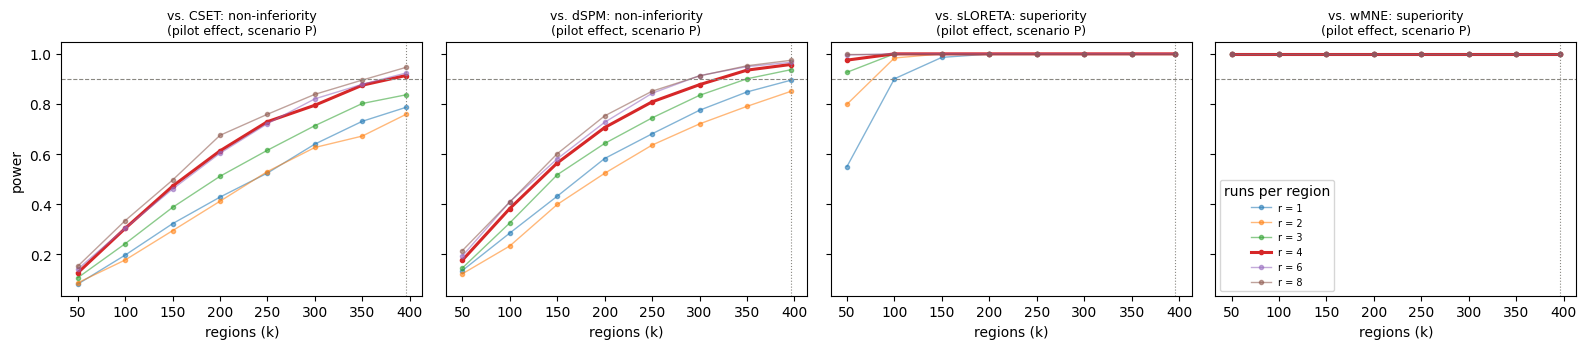

In [11]:
# Figure 1: smallest required power per design, with its compute cost; chosen design outlined.
P = design.pivot(index="r", columns="k", values="min_power").loc[RS, KS]
H = design.pivot(index="r", columns="k", values="hours").loc[RS, KS]
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(P.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto", origin="lower")
for i, r in enumerate(RS):
    for j, k in enumerate(KS):
        p = P.loc[r, k]
        ax.text(j, i, f"{p:.2f}\n{H.loc[r, k]:.0f} h", ha="center", va="center", fontsize=7,
                color="white" if p > 0.6 else "#0b0b0b", fontweight="bold" if p >= POWER_TARGET else "normal")
ci, cj = RS.index(R_CHOSEN), KS.index(K_CHOSEN)
ax.add_patch(plt.Rectangle((cj - 0.5, ci - 0.5), 1, 1, fill=False, ec="#0b0b0b", lw=2.5))
oi, oj = RS.index(OLD_DESIGN[1]), KS.index(OLD_DESIGN[0])
ax.add_patch(plt.Rectangle((oj - 0.5, oi - 0.5), 1, 1, fill=False, ec=LINE_COLOR, lw=1.5, ls="--"))
ax.set_xticks(range(len(KS)), KS); ax.set_yticks(range(len(RS)), RS)
ax.set_xlabel("regions (k)"); ax.set_ylabel("runs per region (r)")
ax.set_title(f"Smallest power over the required tests (bold: ≥ {POWER_TARGET}) and Study I compute time\n"
             f"solid: chosen design ({K_CHOSEN} × {R_CHOSEN}); dashed: previous design (100 × 8)", loc="left", fontsize=9)
fig.colorbar(im, ax=ax, label="smallest required power", fraction=0.04)
fig.tight_layout(); fig.savefig(OUT / "design_heatmap.png", dpi=200)

# Figure 2: each required localization test vs. k, one line per r (chosen r bold)
tests = [(c, "power_noninf", "non-inferiority") for c in NI_REQUIRED] + \
        [(c, "power_holm", "superiority") for c in SUP_REQUIRED]
fig, axes = plt.subplots(1, len(tests), figsize=(4 * len(tests), 3.6), sharey=True)
for ax, (c, col, label) in zip(axes, tests):
    d = P_[P_.competitor == c]
    for r, g in d.groupby("r"):
        ax.plot(g.k, g[col], marker="o", ms=3, lw=2.2 if r == R_CHOSEN else 1, alpha=1 if r == R_CHOSEN else 0.55,
                label=f"r = {r}")
    ax.axhline(POWER_TARGET, color=LINE_COLOR, ls="--", lw=0.8)
    ax.axvline(K_CHOSEN, color=LINE_COLOR, ls=":", lw=0.8)
    ax.set_title(f"vs. {METHOD_LABELS.get(c, c)}: {label}\n(pilot effect, scenario P)", fontsize=9)
    ax.set_xlabel("regions (k)")
axes[0].set_ylabel("power"); axes[-1].legend(fontsize=7, title="runs per region")
fig.tight_layout(); fig.savefig(OUT / "power_curves.png", dpi=200)

## 7. How fragile is the choice? Pilot uncertainty

The variance components come from 50 regions × 4 runs, so they are themselves uncertain, and power computed from
point estimates is optimistic about half the time. Here the normal-model non-inferiority power at the chosen
design is recomputed with σ² and τ² at their upper one-sided 80% confidence limits (σ²: χ² with 50 · 3 df;
τ²: bootstrap over pilot regions), keeping the true difference at the pilot estimate.

In [12]:
df_within = N_PILOT * (R_PILOT - 1)
sigma2_up = sigma2 * df_within / chi2.ppf(0.20, df_within)
rng = np.random.default_rng(11)
tau2_boot = []
for _ in range(2000):
    idx = rng.integers(0, N_PILOT, N_PILOT)
    Db = D_loc[idx]
    mb = Db.mean(1)
    tau2_boot.append(np.maximum(mb.var(0, ddof=1) - Db.var(1, ddof=1).mean(0) / R_PILOT, 0))
tau2_up = np.quantile(np.array(tau2_boot), 0.80, axis=0)

fragility = []
for c in NI_REQUIRED:
    jj = COMPETITORS.index(c)
    mu = CENTER[R_PILOT][jj]
    fragility.append(dict(
        competitor=c, true_diff_mm=mu,
        power_point=ni_power_normal(K_CHOSEN, R_CHOSEN, tau2[jj], sigma2[jj], mu),
        power_upper80=ni_power_normal(K_CHOSEN, R_CHOSEN, tau2_up[jj], sigma2_up[jj], mu),
        sd_between=np.sqrt(tau2[jj]), sd_between_up=np.sqrt(tau2_up[jj]),
        sd_within=np.sqrt(sigma2[jj]), sd_within_up=np.sqrt(sigma2_up[jj])))
fragility = pd.DataFrame(fragility).set_index("competitor")
fragility.round(3)

,true_diff_mm,power_point,power_upper80,sd_between,sd_between_up,sd_within,sd_within_up
competitor,,,,,,,
cset,-2.060,0.872,0.802,10.572,11.845,23.381,24.621
dspm,-0.455,0.982,0.957,15.849,17.483,22.311,23.495


## 8. Minimum detectable effects at the chosen design

Power as a function of the true difference (scenario C: centered, then shifted). Gives the smallest wCSET advantage
detected with 90% power (superiority), and the largest wCSET deficit at which non-inferiority still has 90% power.

,mde_superiority_mm,noninf_power_at_0,max_deficit_noninf_mm,ci_half_width_mm
competitor,,,,
cset,2.68,1.00,2.10,1.72
sloreta,2.12,1.00,2.77,1.45
dspm,3.43,0.98,1.04,2.13
wmne,3.99,0.94,0.37,3.15


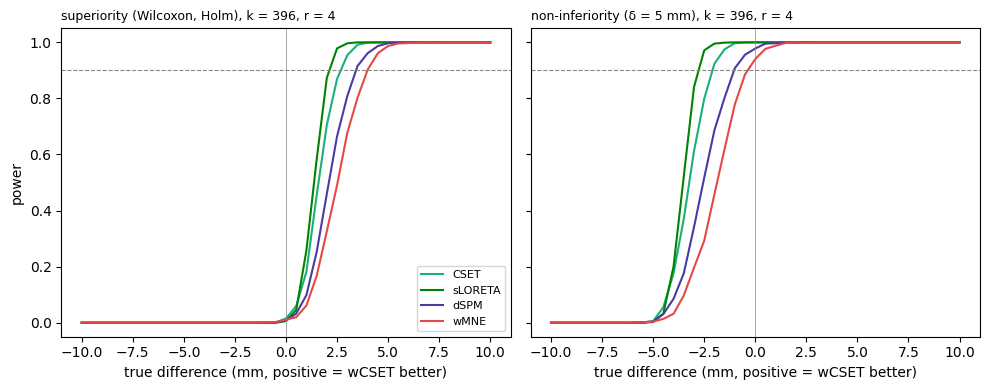

In [13]:
mde_rows = Parallel(n_jobs=N_JOBS)(delayed(run_design)(K_CHOSEN, R_CHOSEN, "C", float(s)) for s in SHIFTS)
mde = pd.DataFrame([row for rows in mde_rows for row in rows])
mde.to_csv(OUT / "mde.tsv", sep="\t", index=False)

def crossing(x, y, level):
    # smallest x where y crosses `level` (linear interpolation); NaN if it never does
    y = np.asarray(y); above = np.flatnonzero(y >= level)
    if not len(above):
        return np.nan
    i = above[0]
    if i == 0:
        return x[0]
    return x[i - 1] + (level - y[i - 1]) * (x[i] - x[i - 1]) / (y[i] - y[i - 1])

mde_tbl = []
for c in COMPETITORS:
    d = mde[mde.competitor == c].sort_values("shift")
    x = d["shift"].to_numpy(); pos = x >= 0
    mde_tbl.append(dict(competitor=c,
                        mde_superiority_mm=crossing(x[pos], d["power_holm"].to_numpy()[pos], POWER_TARGET),
                        noninf_power_at_0=float(d.loc[np.isclose(d["shift"], 0), "power_noninf"].iloc[0]),
                        max_deficit_noninf_mm=-crossing(x, d["power_noninf"].to_numpy(), POWER_TARGET),
                        ci_half_width_mm=float(d.loc[np.isclose(d["shift"], 0), "ci_half_width"].iloc[0])))
mde_tbl = pd.DataFrame(mde_tbl).set_index("competitor")

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for c in COMPETITORS:
    d = mde[mde.competitor == c].sort_values("shift")
    ax[0].plot(d["shift"], d["power_holm"], color=COLORS.get(c), label=METHOD_LABELS.get(c, c))
    ax[1].plot(d["shift"], d["power_noninf"], color=COLORS.get(c))
for a, t in zip(ax, ["superiority (Wilcoxon, Holm)", f"non-inferiority (δ = {DELTA_LOC_MM:g} mm)"]):
    a.axhline(POWER_TARGET, color=LINE_COLOR, ls="--", lw=0.8); a.axvline(0, color=LINE_COLOR, lw=0.5)
    a.set_xlabel("true difference (mm, positive = wCSET better)")
    a.set_title(f"{t}, k = {K_CHOSEN}, r = {R_CHOSEN}", fontsize=9, loc="left")
ax[0].set_ylabel("power"); ax[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "mde_curves.png", dpi=200)
mde_tbl.round(2)

## 9. Cost of Study I and summary for the annex

In [14]:
def cost_table(k, r):
    row = {name: k * r * s / 3600 for name, s in COST_S.items()}
    row["flagship-based total"] = sum(row.values())
    return row

costs = pd.DataFrame({f"previous {OLD_DESIGN[0]} x {OLD_DESIGN[1]}": cost_table(*OLD_DESIGN),
                      f"chosen {K_CHOSEN} x {R_CHOSEN}": cost_table(K_CHOSEN, R_CHOSEN)}).round(1)
noise = {f"noise sweep, 50 x {NOISE_SWEEP_LEVELS} SNR x 3 (current)": 50 * NOISE_SWEEP_LEVELS * 3,
         f"noise sweep, {K_CHOSEN} x {NOISE_SWEEP_LEVELS} SNR x 1": K_CHOSEN * NOISE_SWEEP_LEVELS * 1}
noise_h = {name: n * NOISE_SWEEP_S_PER_RUN / 3600 for name, n in noise.items()}
print("Compute time (h, wall clock, 25 workers):"); print(costs)
print("\nNoise sweep (not part of the design choice; estimate):")
for name, h in noise_h.items():
    print(f"  {name}: {h:.1f} h")

Compute time (h, wall clock, 25 workers):
                            previous 100 x 8  chosen 396 x 4
simulation                               0.4             0.7
solve + score                            2.0             4.0
degradation (11 levels)                  3.7             7.3
surrogates (6 connectomes)               2.0             4.0
flagship-based total                     8.0            15.9

Noise sweep (not part of the design choice; estimate):
  noise sweep, 50 x 9 SNR x 3 (current): 1.5 h
  noise sweep, 396 x 9 SNR x 1: 4.1 h


In [15]:
at = grid[(grid.k == K_CHOSEN) & (grid.r == R_CHOSEN)].set_index(["scenario", "competitor"])
summary = {
    "pilot": {"n_regions": N_PILOT, "n_runs_per_region": R_PILOT, "seed": 2027},
    "decision_rule": {"power_target": POWER_TARGET, "ni_required": NI_REQUIRED, "superiority_required": SUP_REQUIRED,
                      "correlation_effect_scale": CORR_REQUIRED_SCALE, "k_max": K_MAX, "ks": KS, "rs": RS},
    "B": B, "B_cluster": B_CLUSTER, "n_perm_cluster": N_PERM,
    "chosen": {"k": K_CHOSEN, "r": R_CHOSEN, "feasible": bool(feasible), "min_power": float(chosen.min_power),
               "limiting_test": chosen.limiting_test, "hours": float(chosen.hours)},
    "pilot_effects_mm": pilot_tbl["hl"].round(2).to_dict(),
    "sd_between_mm": pilot_tbl["sd_between"].round(2).to_dict(),
    "sd_within_mm": pilot_tbl["sd_within"].round(2).to_dict(),
    "required_power_chosen": {k: round(float(v), 3) for k, v in req_power(K_CHOSEN, R_CHOSEN).items()},
    "required_power_previous": {k: round(float(v), 3) for k, v in req_power(*OLD_DESIGN).items()},
    "pilot_true_diff_mm_fixed": dict(zip(COMPETITORS, np.round(CENTER[R_PILOT], 2))),
    "loc_superiority_power_pilot_effect": at.loc["P", "power_holm"].round(3).to_dict(),
    "loc_noninf_power_pilot_effect": at.loc["P", "power_noninf"].round(3).to_dict(),
    "loc_noninf_power_true_diff_0": at.loc["B", "power_noninf"].round(3).to_dict(),
    "loc_ci_half_width_mm": mde_tbl["ci_half_width_mm"].round(2).to_dict(),
    "loc_mde_superiority_mm": mde_tbl["mde_superiority_mm"].round(2).to_dict(),
    "loc_max_deficit_noninf_mm": mde_tbl["max_deficit_noninf_mm"].round(2).to_dict(),
    "noninf_power_upper80_variances": fragility["power_upper80"].round(3).to_dict(),
    "cost_hours": costs.to_dict(),
    "noise_sweep_hours": {k: round(v, 1) for k, v in noise_h.items()},
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))

lab = lambda c: METHOD_LABELS.get(c, c)
rp = summary["required_power_chosen"]
print(
    f"We chose the number of regions and of runs per region by simulation-based power analysis on a pilot of "
    f"{N_PILOT} regions × {R_PILOT} runs, disjoint from the analysed regions. Power was estimated by a two-stage "
    f"bootstrap of the pilot's region-paired differences ({B} replicates per design), for designs of up to "
    f"{K_MAX} regions and {max(RS)} runs. The design had to reach {POWER_TARGET:.0%} power, at the pilot's "
    f"effects, for localization non-inferiority (δ = {DELTA_LOC_MM:g} mm) against "
    f"{' and '.join(lab(c) for c in NI_REQUIRED)}, for localization superiority against "
    f"{' and '.join(lab(c) for c in SUP_REQUIRED)}, and for the spatial-correlation cluster test at half the "
    f"pilot effect. The cheapest design meeting this was {K_CHOSEN} regions × {R_CHOSEN} runs. " if feasible else
    f"No design up to {K_MAX} × {max(RS)} reached {POWER_TARGET:.0%} on every required test; "
    f"{K_CHOSEN} × {R_CHOSEN} maximized the smallest power ({chosen.min_power:.2f}, {chosen.limiting_test}). ")
print("Power at the chosen design:", rp)

We chose the number of regions and of runs per region by simulation-based power analysis on a pilot of 50 regions × 4 runs, disjoint from the analysed regions. Power was estimated by a two-stage bootstrap of the pilot's region-paired differences (2000 replicates per design), for designs of up to 396 regions and 8 runs. The design had to reach 90% power, at the pilot's effects, for localization non-inferiority (δ = 5 mm) against CSET and dSPM, for localization superiority against sLORETA and wMNE, and for the spatial-correlation cluster test at half the pilot effect. The cheapest design meeting this was 396 regions × 4 runs. 
Power at the chosen design: {'NI vs cset': 0.913, 'NI vs dspm': 0.958, 'superiority vs sloreta': 1.0, 'superiority vs wmne': 1.0, 'correlation (min over 4)': 1.0}


## 10. Caveats

- The pilot regions are the tuning regions, on which wCSET's β, κ and GBF's cutoff were chosen; this may favor
  wCSET slightly in scenarios A and P (scenarios B and C center the differences and are unaffected in location).
- The Hodges–Lehmann estimand (pseudo-median of r-run region means) itself depends on r when errors are bimodal
  (§3). The paper's estimate therefore refers to the chosen r; scenario P holds it at the pilot's 4-run value.
- One subject, one head model and connectome: the variance components may not transfer to other anatomies.
- r > 4 reuses the 4 pilot runs' residuals (extrapolation).
- Non-inferiority is powered at the pilot's own estimate of the difference, itself uncertain (§7); the MDE table
  (§8) shows the deficit range over which the conclusion holds.
- With most of the cortex's regions, neighbouring regions give correlated results, so the effective number of
  independent regions is below k and region-paired tests are slightly anti-conservative.
- This design replaces 100 × 8, chosen earlier, after the 100 × 8 results were seen. The annex must say so, and
  that the change follows this analysis (the earlier design was underpowered for non-inferiority), not the results.